In [2]:
import os
import numpy as np
import mne
import xml.etree.ElementTree as ET

import matplotlib.pyplot as plt
from scipy.interpolate import interp1d

from scipy.signal import butter, filtfilt, spectrogram
from scipy.stats import circmean

from matplotlib.gridspec import GridSpec
from sklearn.decomposition import PCA

import os

In [3]:
from scipy.ndimage import label, gaussian_filter

from convnwb.io import open_h5file, get_files, load_config, save_json, load_json,make_session_name
from convnwb.paths import Paths
 
from spiketools.spatial.occupancy import (compute_occupancy, compute_trial_occupancy,compute_bin_edges,
                                          compute_bin_counts_pos, normalize_bin_counts)
from spiketools.spatial.information import compute_spatial_information
from spiketools.spatial.place import compute_place_bins, compute_trial_place_bins
from spiketools.spatial.utils import compute_pos_ranges, compute_bin_width
from spiketools.spatial.speed import compute_speed

from spiketools.stats.shuffle import shuffle_spikes
from spiketools.stats.permutations import compute_surrogate_stats


from spiketools.plts.stats import plot_surrogates
from spiketools.plts.data import plot_bar, plot_hist, plot_text
from spiketools.plts.spatial import plot_position_by_time,plot_heatmap,create_heatmap_title
from spiketools.plts.style import drop_spines
from spiketools.plts.utils import make_axes
from spiketools.plts.trials import plot_rasters
from spiketools.plts.spatial import plot_heatmap, plot_positions, plot_position_by_time
from spiketools.plts.utils import make_axes, make_grid, get_grid_subplot, save_figure
from spiketools.plts.annotate import color_pvalue,add_vlines,add_hlines
from spiketools.utils.extract import (get_range, get_values_by_time_range,
                                      get_values_by_times, get_value_range,threshold_spikes_by_values)
from spiketools.utils.epoch import epoch_spikes_by_range
from spiketools.utils.data import compute_range
from spiketools.utils import set_random_seed
from spiketools.utils.run import create_methods_list

In [4]:
from lfp_demos.code.get_neuraldata import get_spike_indx

## 4.10.25 new preprocess pipeline: 
it predefines time bins for both LFP, spiking and behaoviral \
id	topdir	session	behavior    familiarity	duration \
250	ec013.15	ec013.156	linear	10	1023.59 \
251	ec013.15	ec013.157	linear	10	631.2 		


In [5]:
bin_size_ms = 100 #ms
session_duration = 1023.59 # second

In [6]:
# --- Set session name and path ---
session = "ec013.156"
base_path = "."  # adjust if your data is nested

eeg_path = os.path.join(base_path, f"{session}.eeg")
xml_path = os.path.join(base_path, f"{session}.xml")

# --- Parse XML ---
tree = ET.parse(xml_path)
root = tree.getroot()

n_channels = int(root.find("acquisitionSystem").find("nChannels").text)
sampling_rate = int(root.find("fieldPotentials").find("lfpSamplingRate").text)
# scale = 0.195e-6  # volts per bit (µV)

# --- Load EEG ---
raw_data = np.fromfile(eeg_path, dtype=np.int16)
n_samples = raw_data.size // n_channels
data = raw_data.reshape((n_samples, n_channels)).T


In [7]:
data.shape

(65, 1279488)

In [8]:
whl_data = np.loadtxt('ec013.156.whl')  # shape: (n_samples, 4)
print(whl_data.shape)

(39985, 4)


In [9]:
# Copy the data for processing
whl_cleaned = whl_data.copy()

# Loop over each column and fill NaNs (replace -1 with np.nan for easier handling)
for i in range(whl_cleaned.shape[1]):
    col = whl_cleaned[:, i]
    # Replace -1 with NaN
    col[col == -1] = np.nan
    # Forward fill
    mask = np.isnan(col)
    idx = np.where(~mask, np.arange(mask.size), 0)
    np.maximum.accumulate(idx, out=idx)
    col = col[idx]
    # Backward fill
    mask = np.isnan(col)
    idx = np.where(~mask, np.arange(mask.size), mask.size - 1)
    np.minimum.accumulate(idx[::-1], out=idx[::-1])
    col = col[idx]
    # Replace back in the cleaned data
    whl_cleaned[:, i] = col

# Extract LED positions
x1, y1, x2, y2 = whl_cleaned.T


In [10]:
# fs_pos = 39.0625  # position sampling rate
fs_LFP = 1250 # LFP sampling rate
fs_LFP0 = data.shape[1] / session_duration

duration_lfp = data.shape[1] / fs_LFP # duration of LFP
fs_pos =  whl_data.shape[0] / duration_lfp

print('LFP duration: ' + str(duration_lfp))
print('LFP sampling rate from calculation duration/sample: ' + str(fs_LFP0))
print('Duration according to METADATA: ' + str(session_duration))
print('Position(camera) sampling rate: ' + str(fs_pos))

LFP duration: 1023.5904
LFP sampling rate from calculation duration/sample: 1250.0004884768316
Duration according to METADATA: 1023.59
Position(camera) sampling rate: 39.06347695328131


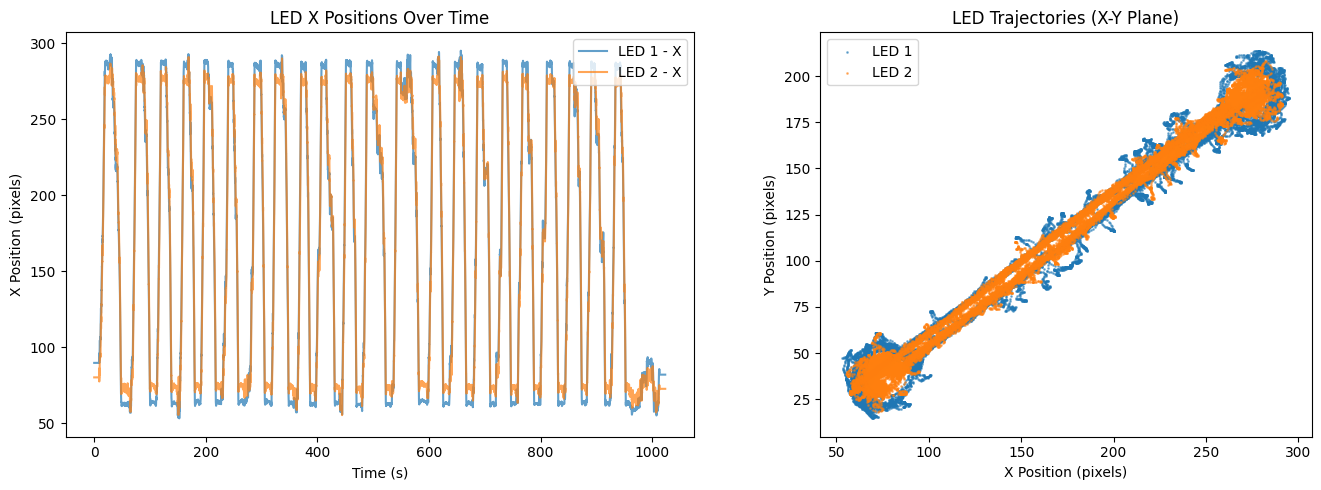

In [11]:
# Create time index based on sampling rate
time = np.arange(whl_cleaned.shape[0]) / fs_pos

# Create subplots: one for time vs LED X coordinates, another for the 2D trajectory
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: LED X positions over time
axs[0].plot(time, x1, label='LED 1 - X', alpha=0.7)
axs[0].plot(time, x2, label='LED 2 - X', alpha=0.7)
axs[0].set_title("LED X Positions Over Time")
axs[0].set_xlabel("Time (s)")
axs[0].set_ylabel("X Position (pixels)")
axs[0].legend(loc = 'upper right')

# Subplot 2: Scatter plot of (x, y) positions
axs[1].scatter(x1, y1, s=1, alpha=0.5, label='LED 1')
axs[1].scatter(x2, y2, s=1, alpha=0.5, label='LED 2')
axs[1].set_title("LED Trajectories (X-Y Plane)")
axs[1].set_xlabel("X Position (pixels)")
axs[1].set_ylabel("Y Position (pixels)")
axs[1].set_aspect('equal', 'box')
axs[1].legend()

plt.tight_layout()
plt.show()


### sliding window

In [12]:
LFP_window_sample_size = int(fs_LFP * bin_size_ms/ 1000)
pos_window_sample_size = int(fs_pos * bin_size_ms / 1000)
n_channels, n_samples = data.shape
n_windows = (n_samples) // LFP_window_sample_size

print("Number of bins for all modalities: " + str(n_windows))
print("Size of bin in millisecond: " + str(bin_size_ms))
print("Number of samples in each bin for LFP: " + str(LFP_window_sample_size))
print("Number of samples in each bin for Position: " + str(pos_window_sample_size))

Number of bins for all modalities: 10235
Size of bin in millisecond: 100
Number of samples in each bin for LFP: 125
Number of samples in each bin for Position: 3


In [13]:
# --- Step 1: Linearize position using PCA ---
# Use average of two LEDs as a single (x, y) position per frame
avg_x = (x1 + x2) / 2
avg_y = (y1 + y2) / 2
position_2d = np.vstack([avg_x, avg_y]).T

# Apply PCA to get 1D linearized position
pca = PCA(n_components=1)
linearized_position = pca.fit_transform(position_2d).flatten()

# Compute speed from linearized position (first derivative)
linearized_speed = np.abs(np.gradient(linearized_position) * fs_pos)

# Compute head direction in radians using LED1 and LED2
dx = x2 - x1
dy = y2 - y1
head_direction = np.arctan2(dy, dx)  # ranges from -pi to pi

n_windows is same across modalities

In [14]:
bands = {
    # "delta": (1, 4),
    "theta": (4, 12),
    # "beta": (12, 30),
    "low_gamma": (30, 55),
    "high_gamma": (65, 100)
}


In [15]:
def butter_bandpass_filter(data, lowcut, highcut, fs, order=4):
    nyquist = 0.5 * fs
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype='band')
    return filtfilt(b, a, data)

In [16]:
first_channel = data[0,0:2000]

filtered_signals = []
for lowcut, highcut in bands.values():
    filtered = butter_bandpass_filter(first_channel, lowcut, highcut, fs_LFP)
    filtered_signals.append(filtered)

combined_signal = np.sum(filtered_signals, axis=0)

f_spectrogram, t_spectrogram, Sxx = spectrogram(combined_signal, fs=fs_LFP, nperseg=1024, noverlap=512)

In [17]:
def bandpower(data, fs, band, win_samples):
    low, high = band
    nyq = 0.5 * fs
    b, a = butter(4, [low/nyq, high/nyq], btype='band')
    filtered = filtfilt(b, a, data, axis=1)
    power = filtered**2
    return np.mean(power[:, :win_samples], axis=1)  # mean power per channel

In [18]:
bin_power = []
bin_linear_pos = []
bin_speed = []
bin_head_dir = []

for i in range(n_windows):
    LFP_start = int(i * LFP_window_sample_size)
    LFP_end = int(LFP_start + LFP_window_sample_size)

    window_data = data[:, LFP_start:LFP_end]
    feature_vector = []
    
    # --- LFP Band Power Features ---
    for band in bands.values():
        power = bandpower(window_data, fs_LFP, band, LFP_window_sample_size)  # shape: (n_channels,)
        feature_vector.extend(power)
    bin_power.append(feature_vector)

    pos_start = i * pos_window_sample_size
    pos_end = pos_start + pos_window_sample_size
    # Protect against overrun
    if pos_end > len(linearized_position):
        break


    # Position
    pos_bin = np.nanmean(linearized_position[pos_start:pos_end])
    displacement = np.abs(linearized_position[pos_end - 1] - linearized_position[pos_start])
    speed_bin = displacement / (bin_size_ms/1000)

    head_dir_bin = circmean(head_direction[pos_start:pos_end], high=np.pi, low=-np.pi)

    bin_linear_pos.append(pos_bin)
    bin_speed.append(speed_bin)
    bin_head_dir.append(head_dir_bin)

# Convert to arrays
bin_power = np.array(bin_power)
bin_linear_pos = np.array(bin_linear_pos)
bin_speed = np.array(bin_speed)
bin_head_dir = np.array(bin_head_dir)




In [19]:
print("Shape of bin_power: ", str(bin_power.shape))
print("Shape of bin_linear_pos: ", str(bin_linear_pos.shape))
print("Shape of bin_speed: ", str(bin_speed.shape))
print("Shape of bin_head_dir: ", str(bin_head_dir.shape))


Shape of bin_power:  (10235, 195)
Shape of bin_linear_pos:  (10235,)
Shape of bin_speed:  (10235,)
Shape of bin_head_dir:  (10235,)


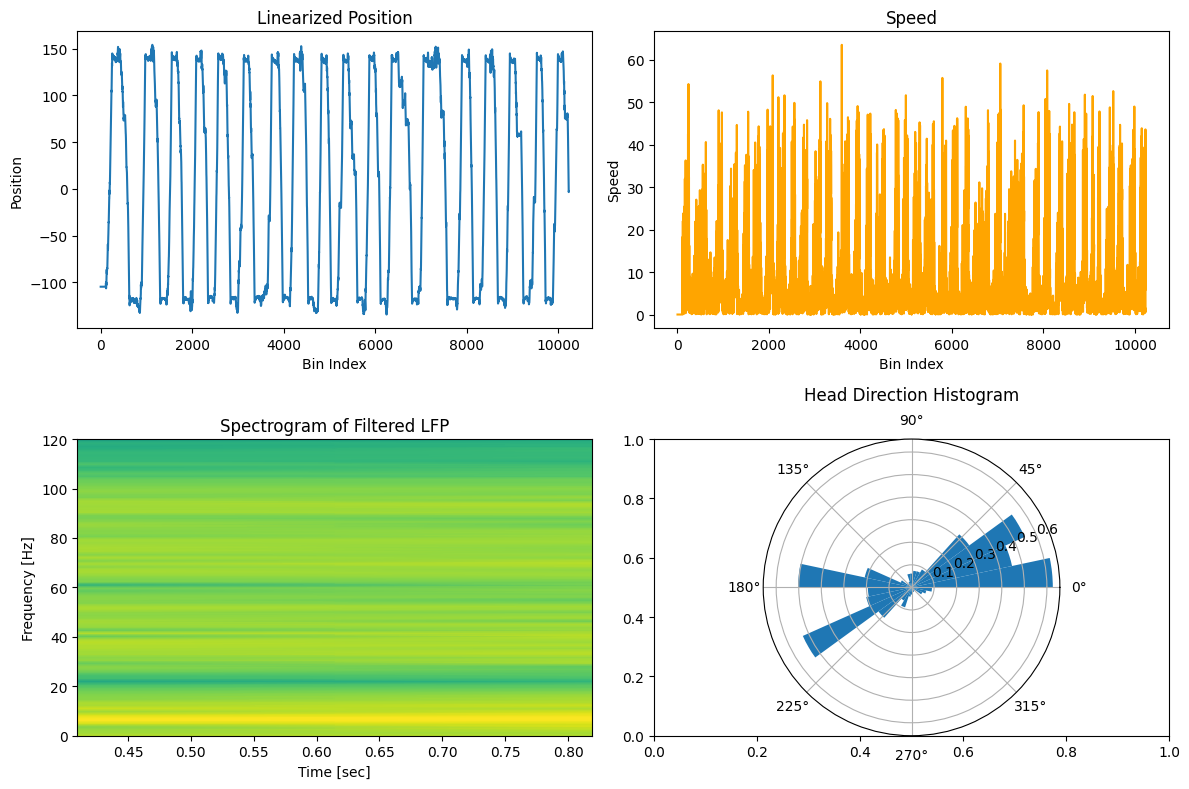

In [20]:
# Create 2x2 subplot
fig, axs = plt.subplots(2, 2, figsize=(12, 8))

# Plot 1: Linearized position over bins
axs[0, 0].plot(bin_linear_pos, label='Linearized Position')
axs[0, 0].set_title("Linearized Position")
axs[0, 0].set_xlabel("Bin Index")
axs[0, 0].set_ylabel("Position")
# axs[0, 0].legend(loc = 'upper right')

# Plot 2: Speed over bins
axs[0, 1].plot(bin_speed, label='Speed', color='orange')
axs[0, 1].set_title("Speed")
axs[0, 1].set_xlabel("Bin Index")
axs[0, 1].set_ylabel("Speed")
# axs[0, 1].legend()

# Plot 3: Power summary over time (just the first channel, first band for example)

pcm = axs[1,0].pcolormesh(t_spectrogram, f_spectrogram, 10 * np.log10(Sxx), shading='gouraud')
axs[1,0].set_title('Spectrogram of Filtered LFP')
axs[1,0].set_ylabel('Frequency [Hz]')
axs[1,0].set_xlabel('Time [sec]')
axs[1,0].set_ylim(0, 120)

# Plot 4: Circular histogram for head direction
axs[1, 1] = plt.subplot(2, 2, 4, polar=True)
axs[1, 1].hist(bin_head_dir, bins=30, density=True)
axs[1, 1].set_title("Head Direction Histogram", va='bottom')

plt.tight_layout()
plt.show()


In [21]:
# Compute dimensions and print summary
summary = {
    "LFP power features (bin_power)": bin_power.shape,
    "Linearized position (bin_linear_pos)": bin_linear_pos.shape,
    "Speed (bin_speed)": bin_speed.shape,
    "Head direction (bin_head_dir)": bin_head_dir.shape
}

for name, shape in summary.items():
    print(f"{name}: {shape}")


LFP power features (bin_power): (10235, 195)
Linearized position (bin_linear_pos): (10235,)
Speed (bin_speed): (10235,)
Head direction (bin_head_dir): (10235,)


In [22]:
# Step 1: Get main direction of track from PCA
pca_vec = pca.components_[0]  # shape: (2,)
# Get PCA track direction in radians
theta_track = np.arctan2(pca_vec[1], pca_vec[0])  # from PCA axis

# Compare each bin head direction to PCA track direction
angle_diff = bin_head_dir - theta_track
cos_diff = np.cos(angle_diff)

# Classify based on alignment with track axis
bin_head_dir_binary = np.where(cos_diff >= 0, 1, -1)


## Get Spiking data

In [23]:
spike_data_folder = './ec013.156/'
fs_spike = 20000 
spike_data, n_units = get_spike_indx(spike_data_folder)
n_elec = len(spike_data)
print(' ')
print('Number of electrode: ',n_elec)
print('Total Units: ',n_units)

Elec 0: 21 Clusters
Elec 1: 20 Clusters
Elec 2: 18 Clusters
Elec 3: 16 Clusters
Elec 4: 7 Clusters
Elec 5: 7 Clusters
Elec 6: 7 Clusters
Elec 7: 3 Clusters
 
Number of electrode:  8
Total Units:  99


In [24]:
all_spikes = []
for i in range(len(spike_data)):
    spike_inds = spike_data[str(i)]
    for i,(units, unit_spikes)in enumerate(spike_inds.items()):
        spikes = unit_spikes/fs_spike
        all_spikes.append(spikes)

In [25]:
# add one more window for np.histogram
binned_spikes = []
for spikes in all_spikes:
    spike_bins = np.histogram(spikes, bins=np.arange(0, (n_windows+1)*bin_size_ms/1000, bin_size_ms/1000))[0]
    binned_spikes.append(spike_bins)
binned_spikes = np.array(binned_spikes)
# Check for NaN values in binned_spikes
print("Shape of binned_spikes:", binned_spikes.shape)
print("Number of NaN values:", np.isnan(binned_spikes).sum())
print("Percentage of NaN values:", (np.isnan(binned_spikes).sum() / binned_spikes.size) * 100, "%")
input_spike = binned_spikes.T

Shape of binned_spikes: (83, 10235)
Number of NaN values: 0
Percentage of NaN values: 0.0 %


In [26]:
print("input size:")
print("LFP power: " + str(bin_power.shape))
print("Spikes: " + str(input_spike.shape))

input size:
LFP power: (10235, 195)
Spikes: (10235, 83)


In [27]:
# import pickle

# feature_dict = {
#     'bin_power': bin_power,
#     'input_spike': input_spike,
#     'bin_linear_pos': bin_linear_pos,
#     'bin_head_dir': bin_head_dir,
#     'bin_head_dir_binary': bin_head_dir_binary,
#     'bin_speed': bin_speed,
#     'fs_LFP': fs_LFP,
#     'fs_pos': fs_pos,
#     'duration_LFP': duration_lfp,
#     'bin_size_ms': bin_size_ms,
#     'bands': bands
# }

# with open('ec013_156_preprocessed.pkl', 'wb') as f:
#     pickle.dump(feature_dict, f)


## visualization


## Experiment with Cebra

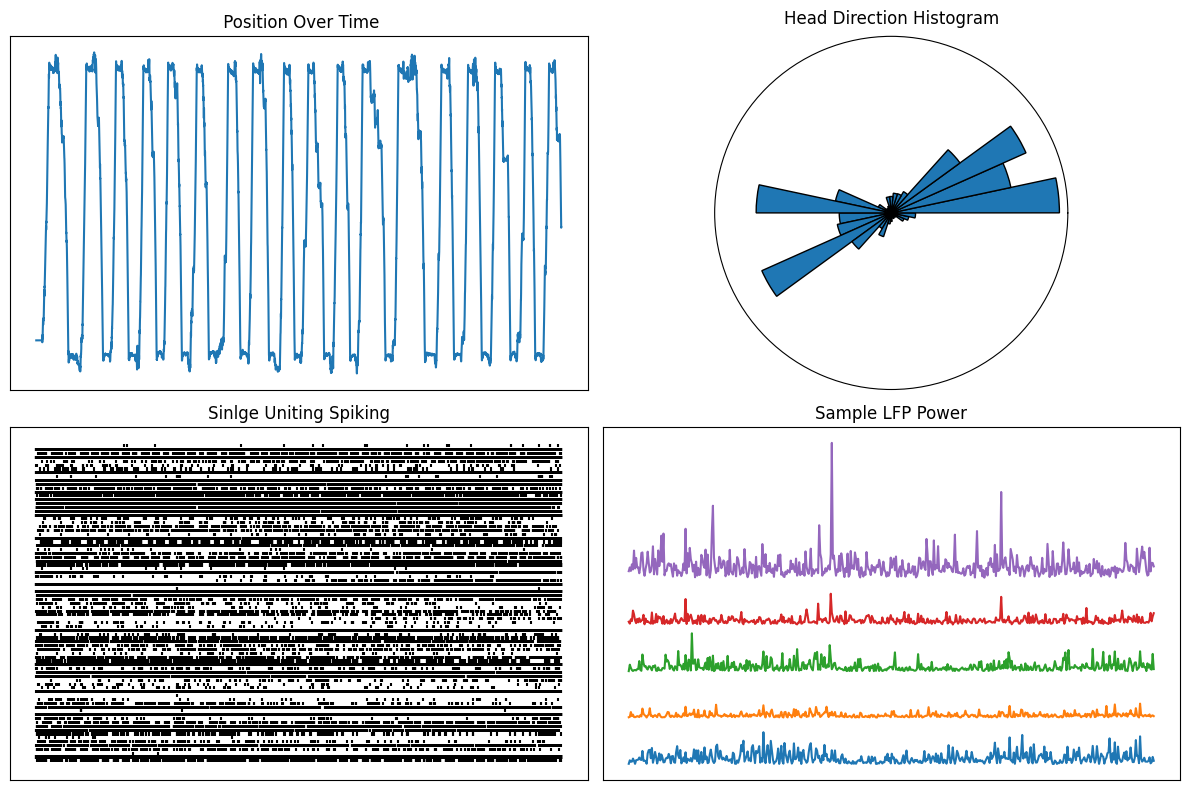

In [78]:
# Create 2x2 subplot
fig, axs = plt.subplots(2, 2, figsize=(12, 8))

# === Plot 1: Linearized position ===
axs[0, 0].plot(bin_linear_pos, label='Linearized Position')
axs[0, 0].set_title(" Position Over Time")

axs[0, 0].set_xticks([])
axs[0, 0].set_yticks([])

# === Replace axs[0,1] with a polar subplot ===
# Remove the original cartesian axes
fig.delaxes(axs[0, 1])
axs[0, 1] = fig.add_subplot(2, 2, 2, polar=True)

# Plot circular histogram
num_bins = 30
counts, bins = np.histogram(bin_head_dir, bins=num_bins, density=True)
widths = np.diff(bins)
axs[0, 1].bar(bins[:-1], counts, width=widths, bottom=0.0, align='edge', edgecolor='k')

# axs[0, 1].spines['polar'].set_visible(False)
axs[0, 1].set_title("Head Direction Histogram", va='bottom')
axs[0, 1].set_xticks([])
axs[0, 1].set_yticks([])

# === Plot 3: Spike raster (all neurons) ===
spike_times_list = []
for neuron_idx in range(input_spike.shape[1]):
    spike_bins = np.where(input_spike[:, neuron_idx] > 0)[0]
    spike_times_list.append(spike_bins)

axs[1, 0].eventplot(spike_times_list, colors='black', lineoffsets=np.arange(input_spike.shape[1]), linelengths=0.8)
axs[1, 0].set_title('Sinlge Uniting Spiking')
axs[1, 0].set_xticks([])
axs[1, 0].set_yticks([])

# === Plot 4: Sample LFP power traces with vertical offset ===
sample_indices = [0, 30, 60, 90, 120]
offset = 50000
for i, idx in enumerate(sample_indices):
    axs[1, 1].plot(bin_power[0:500, idx] + i * offset, label=f'Ch {idx}')

axs[1, 1].set_title('Sample LFP Power')
axs[1, 1].set_xticks([])
axs[1, 1].set_yticks([])

plt.tight_layout()
plt.show()

In [52]:
from cebra import CEBRA
import cebra.integrations.plotly


In [53]:
max_iterations = 10000
output_dimension = 32

### Cebra-LFP-time

In [54]:
LFP_cebra_model_time = CEBRA(model_architecture='offset10-model',
                        batch_size=512,
                        learning_rate=3e-4,
                        temperature_mode = "auto",
                        output_dimension = output_dimension,
                        max_iterations=max_iterations,
                        distance='cosine',
                        conditional='time',
                        device='cuda_if_available',
                        verbose=True,
                        time_offsets=10)

In [55]:
LFP_cebra_model_time.fit(bin_power)
LFP_time_embedding = LFP_cebra_model_time.transform(bin_power)

pos: -8.5722 neg:  10.7748 total:  2.2025 temperature:  0.1000: 100%|██████████| 10000/10000 [02:00<00:00, 83.01it/s]


In [56]:
fig = cebra.integrations.plotly.plot_embedding_interactive(LFP_time_embedding, embedding_labels=bin_linear_pos, title = "CEBRA-LFP-Time, color:position", cmap = "inferno")
fig.show()

<Figure size 500x500 with 0 Axes>

In [57]:
fig = cebra.integrations.plotly.plot_embedding_interactive(LFP_time_embedding, embedding_labels=bin_speed, title = "CEBRA-Time, color:speeds", cmap = "inferno")
fig.show()

<Figure size 500x500 with 0 Axes>

In [58]:
fig = cebra.integrations.plotly.plot_embedding_interactive(LFP_time_embedding, embedding_labels=bin_head_dir, title = "CEBRA-Time, color:head_dirs", cmap = "inferno")
fig.show()

<Figure size 500x500 with 0 Axes>

### Cebra-Spiking-Time

In [59]:
SP_cebra_model_time = CEBRA(model_architecture='offset10-model',
                        batch_size=512,
                        learning_rate=3e-4,
                        temperature_mode = "auto",
                        output_dimension = output_dimension,
                        max_iterations=max_iterations,
                        distance='cosine',
                        conditional='time',
                        device='cuda_if_available',
                        verbose=True,
                        time_offsets=10)

In [60]:
SP_cebra_model_time.fit(input_spike)
SP_time_embedding = SP_cebra_model_time.transform(input_spike)

pos: -8.3982 neg:  10.0628 total:  1.6646 temperature:  0.1000: 100%|██████████| 10000/10000 [02:08<00:00, 77.77it/s]


In [61]:
fig = cebra.integrations.plotly.plot_embedding_interactive(SP_time_embedding, embedding_labels=bin_linear_pos, title = "CEBRA-Spike-Time, color:position", cmap = "inferno")
fig.show()

<Figure size 500x500 with 0 Axes>

In [62]:
fig = cebra.integrations.plotly.plot_embedding_interactive(SP_time_embedding, embedding_labels=bin_speed, title = "CEBRA-Spiking-Time, color:speeds", cmap = "inferno")
fig.show()

<Figure size 500x500 with 0 Axes>

In [63]:
fig = cebra.integrations.plotly.plot_embedding_interactive(SP_time_embedding, embedding_labels=bin_head_dir, title = "CEBRA-Spiking-Time, color:head_dirs_raw", cmap = "inferno")
fig.show()

<Figure size 500x500 with 0 Axes>

### Cebra-LFP-Position

In [64]:
LFP_cebra_model_position = CEBRA(model_architecture='offset10-model',
                        batch_size=512,
                        learning_rate=3e-4,
                        temperature_mode = "auto",
                        output_dimension = output_dimension,
                        max_iterations=max_iterations,
                        distance='cosine',
                        conditional='time_delta',
                        device='cuda_if_available',
                        verbose=True,
                        time_offsets=10)

In [65]:
LFP_cebra_model_position.fit(bin_power, bin_linear_pos)
LFP_position_embedding = LFP_cebra_model_position.transform(bin_power)

pos: -7.9874 neg:  13.0009 total:  5.0135 temperature:  0.1000: 100%|██████████| 10000/10000 [02:41<00:00, 61.79it/s]


In [66]:
fig = cebra.integrations.plotly.plot_embedding_interactive(LFP_position_embedding, embedding_labels=bin_linear_pos, title = "CEBRA-LFP-Position", cmap = "inferno")
fig.show()

<Figure size 500x500 with 0 Axes>

### Cebra-Spiking-Position

In [67]:
SP_cebra_model_position = CEBRA(model_architecture='offset10-model',
                        batch_size=512,
                        learning_rate=3e-4,
                        temperature_mode = "auto",
                        output_dimension = output_dimension,
                        max_iterations=max_iterations,
                        distance='cosine',
                        conditional='time_delta',
                        device='cuda_if_available',
                        verbose=True,
                        time_offsets=10)

In [68]:
SP_cebra_model_position.fit(input_spike, bin_linear_pos)
SP_position_embedding = SP_cebra_model_position.transform(input_spike)

pos: -7.7598 neg:  12.5688 total:  4.8090 temperature:  0.1000: 100%|██████████| 10000/10000 [02:32<00:00, 65.48it/s]


In [69]:
fig = cebra.integrations.plotly.plot_embedding_interactive(SP_position_embedding, embedding_labels=bin_linear_pos, title = "CEBRA-Spiking-Position", cmap = "inferno")
fig.show()

<Figure size 500x500 with 0 Axes>

### Cebra-LFP-Speed

In [70]:
LFP_cebra_model_speed = CEBRA(model_architecture='offset10-model',
                        batch_size=512,
                        learning_rate=3e-4,
                        temperature_mode = "auto",
                        output_dimension = output_dimension,
                        max_iterations=max_iterations,
                        distance='cosine',
                        conditional='time_delta',
                        device='cuda_if_available',
                        verbose=True,
                        time_offsets=10)

In [71]:
LFP_cebra_model_speed.fit(bin_power, bin_speed)
LFP_speed_embedding = LFP_cebra_model_speed.transform(bin_power)

pos: -7.2633 neg:  13.0711 total:  5.8077 temperature:  0.1000: 100%|██████████| 10000/10000 [02:42<00:00, 61.70it/s]


In [72]:
fig = cebra.integrations.plotly.plot_embedding_interactive(LFP_speed_embedding, embedding_labels=bin_speed, title = "CEBRA-LFP-Speed", cmap = "inferno")
fig.show()

<Figure size 500x500 with 0 Axes>

### Cebra-Spiking-Speed

In [73]:
SP_cebra_model_speed = CEBRA(model_architecture='offset10-model',
                        batch_size=512,
                        learning_rate=3e-4,
                        temperature_mode = "auto",
                        output_dimension = output_dimension,
                        max_iterations=max_iterations,
                        distance='cosine',
                        conditional='time_delta',
                        device='cuda_if_available',
                        verbose=True,
                        time_offsets=10)

In [74]:
SP_cebra_model_speed.fit(input_spike, bin_speed)
SP_speed_embedding = SP_cebra_model_speed.transform(input_spike)

pos: -7.0649 neg:  12.8829 total:  5.8179 temperature:  0.1000: 100%|██████████| 10000/10000 [02:36<00:00, 63.81it/s]


In [75]:
fig = cebra.integrations.plotly.plot_embedding_interactive(SP_speed_embedding, embedding_labels=bin_speed, title = "CEBRA-Spiking-Speed", cmap = "inferno")
fig.show()

<Figure size 500x500 with 0 Axes>

### Cebra-LFP-Head_dir Raw

In [76]:
LFP_cebra_model_head_dir_raw = CEBRA(model_architecture='offset10-model',
                        batch_size=512,
                        learning_rate=3e-4,
                        temperature_mode = "auto",
                        output_dimension = output_dimension,
                        max_iterations=max_iterations,
                        distance='cosine',
                        conditional='time_delta',
                        device='cuda_if_available',
                        verbose=True,
                        time_offsets=10)

In [77]:
LFP_cebra_model_head_dir_raw.fit(bin_power, bin_head_dir)
LFP_head_dir_raw_embedding = LFP_cebra_model_head_dir_raw.transform(bin_power)

pos: -7.5079 neg:  13.0050 total:  5.4972 temperature:  0.1000: 100%|██████████| 10000/10000 [02:47<00:00, 59.73it/s]


In [78]:
fig = cebra.integrations.plotly.plot_embedding_interactive(LFP_head_dir_raw_embedding, embedding_labels=bin_head_dir, title = "Cebra-LFP-Head_dir Raw", cmap = "inferno")
fig.show()

<Figure size 500x500 with 0 Axes>

### Cebra-Spiking-Head_dir Raw

In [79]:
SP_cebra_model_head_dir_raw = CEBRA(model_architecture='offset10-model',
                        batch_size=512,
                        learning_rate=3e-4,
                        temperature_mode = "auto",
                        output_dimension = output_dimension,
                        max_iterations=max_iterations,
                        distance='cosine',
                        conditional='time_delta',
                        device='cuda_if_available',
                        verbose=True,
                        time_offsets=10)

In [80]:
SP_cebra_model_head_dir_raw.fit(input_spike, bin_head_dir)
SP_head_dir_raw_embedding = SP_cebra_model_head_dir_raw.transform(input_spike)

pos: -7.7542 neg:  13.0324 total:  5.2782 temperature:  0.1000: 100%|██████████| 10000/10000 [02:33<00:00, 65.28it/s]


In [81]:
fig = cebra.integrations.plotly.plot_embedding_interactive(SP_head_dir_raw_embedding, embedding_labels=bin_head_dir, title = "Cebra-Spiking-Head_dir Raw", cmap = "inferno")
fig.show()

<Figure size 500x500 with 0 Axes>

### Cebra-LFP-Head_dir_binary

In [88]:
LFP_cebra_model_head_dir_binary = CEBRA(model_architecture='offset10-model',
                        batch_size=512,
                        learning_rate=3e-4,
                        temperature_mode = 'auto',
                        output_dimension = output_dimension,
                        max_iterations=max_iterations,
                        distance='cosine',
                        conditional='time_delta',
                        device='cuda_if_available',
                        verbose=True,
                        time_offsets=10)

In [89]:
LFP_cebra_model_head_dir_binary.fit(bin_power, bin_head_dir_binary + 1)
LFP_head_dir_binary_embedding = LFP_cebra_model_head_dir_binary.transform(bin_power)

  0%|          | 0/10000 [00:00<?, ?it/s]

pos: -2.7641 neg:  8.3434 total:  5.5793 temperature:  0.3510: 100%|██████████| 10000/10000 [02:36<00:00, 63.82it/s]


In [90]:
fig = cebra.integrations.plotly.plot_embedding_interactive(LFP_head_dir_binary_embedding, embedding_labels=bin_head_dir_binary, title = "Cebra-LFP-Head_dir_binary", cmap = "inferno")
fig.show()

<Figure size 500x500 with 0 Axes>

### Cebra-Spiking-Head_dir_binary

In [91]:
SP_cebra_model_head_dir_binary = CEBRA(model_architecture='offset10-model',
                        batch_size=512,
                        learning_rate=3e-4,
                        temperature_mode="auto",
                        output_dimension = output_dimension,
                        max_iterations=max_iterations,
                        distance='cosine',
                        conditional='time_delta',
                        device='cuda_if_available',
                        verbose=True,
                        time_offsets=10)

In [92]:
SP_cebra_model_head_dir_binary.fit(input_spike, bin_head_dir_binary + 1)
SP_head_dir_binary_embedding = SP_cebra_model_head_dir_binary.transform(input_spike)

pos: -3.3212 neg:  8.8767 total:  5.5555 temperature:  0.2988: 100%|██████████| 10000/10000 [02:31<00:00, 66.02it/s]


In [93]:
fig = cebra.integrations.plotly.plot_embedding_interactive(SP_head_dir_binary_embedding, embedding_labels=bin_head_dir_binary, title = "Cebra-Spiking-Head_dir_binary", cmap = "inferno")
fig.show()

<Figure size 500x500 with 0 Axes>